# Sentinel-2 land cover: how well do simple models do, and where do they fail?

This notebook runs the whole project in order. The heavy steps (CNN training) save their results to `results/` and `models/`, so by default the notebook loads those instead of retraining. Set `RETRAIN = True` to run everything from scratch (about 2.5 hours on my laptop CPU).

Data needed first: unzip `EuroSAT_MS.zip` into `data/raw/` (see README).

In [1]:
import sys, json
sys.path.insert(0, '../src')
import pandas as pd
from IPython.display import Image, display

RETRAIN = False
RES = '../results/'

## 1. Data
13-band EuroSAT, 27,000 patches of 64x64 pixels, 10 classes. One fixed 80/20 stratified split is used for every model.

In [2]:
from data import load, split, BANDS
import numpy as np
X, y, classes = load()
tr, te = split(y)
print(X.shape, len(tr), len(te))
print(dict(zip(classes, np.bincount(y))))

(27000, 13, 64, 64) 21600 5400
{'AnnualCrop': np.int64(3000), 'Forest': np.int64(3000), 'HerbaceousVegetation': np.int64(3000), 'Highway': np.int64(2500), 'Industrial': np.int64(2500), 'Pasture': np.int64(2000), 'PermanentCrop': np.int64(2500), 'Residential': np.int64(3000), 'River': np.int64(2500), 'SeaLake': np.int64(3000)}


## 2. Baseline: band means/stds + NDVI, NDWI, NDBI, then logistic regression and random forest

In [3]:
if RETRAIN:
    import baseline; baseline.main()
print(json.load(open(RES + 'baseline_summary.json')))
pd.read_csv(RES + 'random_forest_report.csv', index_col=0)

{'logreg': 0.9037, 'random_forest': 0.9124}


,precision,recall,f1-score,support
AnnualCrop,0.894,0.895,0.894,600.000
Forest,0.988,0.993,0.991,600.000
HerbaceousVegetation,0.908,0.965,0.935,600.000
Highway,0.779,0.696,0.735,500.000
Industrial,0.910,0.928,0.919,500.000
Pasture,0.902,0.900,0.901,400.000
PermanentCrop,0.875,0.880,0.877,500.000
Residential,0.903,0.900,0.902,600.000
River,0.934,0.938,0.936,500.000
SeaLake,0.992,0.990,0.991,600.000


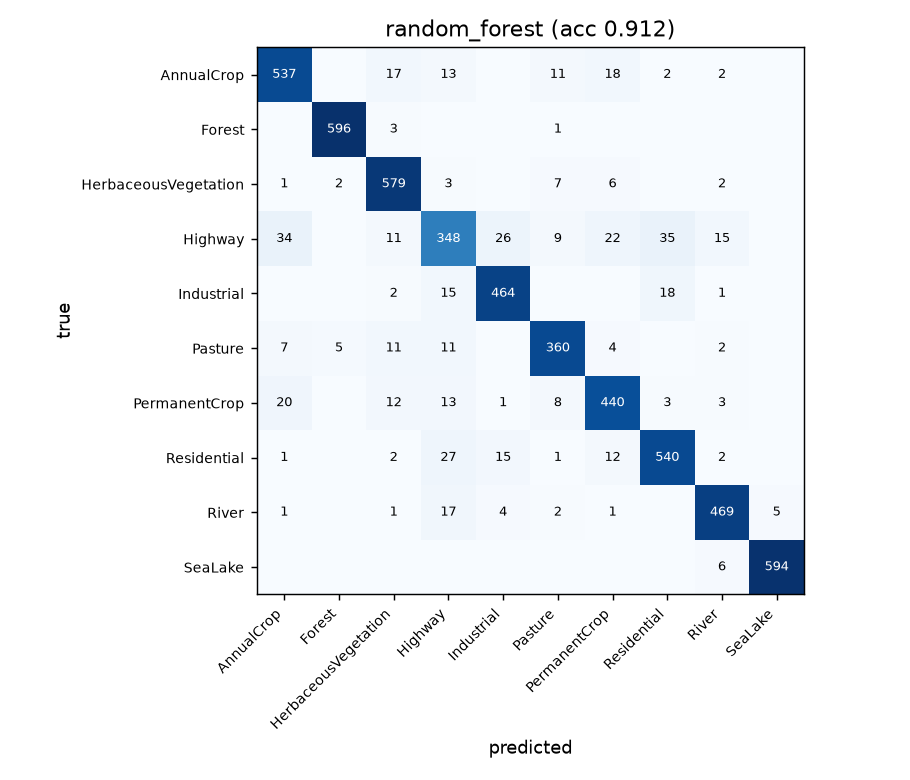

In [4]:
display(Image(RES + 'cm_random_forest.png'))

## 3. Small CNN: RGB only vs all 13 bands
Same architecture, same split, same 12 epochs. Only the input bands change.

In [5]:
if RETRAIN:
    import cnn
    for name, bands in [('rgb', cnn.RGB), ('all13', list(range(13)))]:
        cnn.train(name, bands)
print(json.load(open(RES + 'cnn_summary.json')))
rep = {n: pd.read_csv(RES + f'cnn_{n}_report.csv', index_col=0)['recall'] for n in ['rgb', 'all13']}
pd.DataFrame(rep).iloc[:10]

{'rgb': 0.9706, 'all13': 0.9824}


,rgb,all13
AnnualCrop,0.960,0.985
Forest,0.990,0.998
HerbaceousVegetation,0.962,0.975
Highway,0.962,0.956
Industrial,0.986,0.992
Pasture,0.958,0.960
PermanentCrop,0.942,0.962
Residential,0.993,0.997
River,0.954,0.994
SeaLake,0.988,0.993


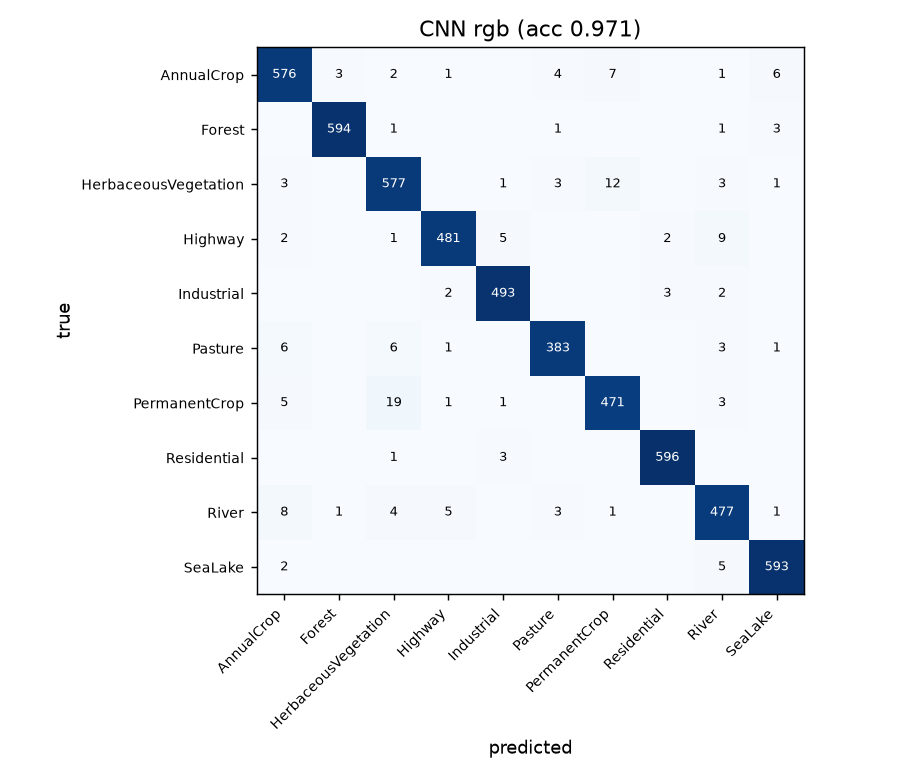

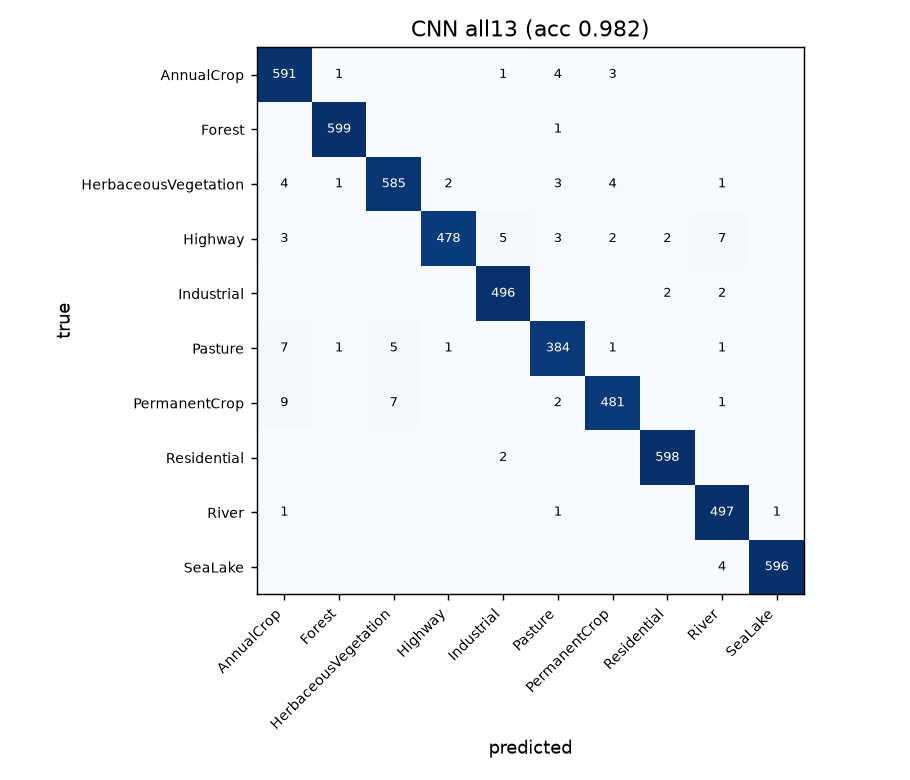

In [6]:
display(Image(RES + 'cm_cnn_rgb.png'))
display(Image(RES + 'cm_cnn_all13.png'))

## 4. Failure tests
Knock out groups of bands, add noise, and check how confident the model is when it is wrong.

In [7]:
if RETRAIN:
    import failure; failure.main()
ft = pd.read_csv(RES + 'failure_tests.csv')
ft

,test,setting,model,acc,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
0,drop bands,none,all13,0.982,0.985,0.998,0.975,0.956,0.992,0.960,0.962,0.997,0.994,0.993
1,drop bands,"coastal+vapour+cirrus (B01,B09,B10)",all13,0.794,0.953,0.620,0.657,0.856,0.860,0.462,0.728,0.775,0.974,0.983
2,drop bands,"visible (B02,B03,B04)",all13,0.448,0.715,0.023,0.560,0.420,0.078,0.032,0.130,0.385,0.988,0.982
3,drop bands,"red edge (B05,B06,B07)",all13,0.799,0.597,0.738,0.865,0.884,0.910,0.932,0.232,0.908,0.930,0.997
4,drop bands,"NIR (B08,B8A)",all13,0.599,0.860,0.688,0.905,0.696,0.972,0.120,0.598,0.920,0.044,0.010
5,drop bands,"SWIR (B11,B12)",all13,0.621,0.783,0.105,0.572,0.834,0.980,0.372,0.588,0.947,0.734,0.318
6,noise,sigma=0.0,rgb,0.971,0.960,0.990,0.962,0.962,0.986,0.958,0.942,0.993,0.954,0.988
7,noise,sigma=0.1,rgb,0.589,0.423,0.717,0.505,0.920,0.950,0.290,0.810,0.998,0.248,0.023
8,noise,sigma=0.25,rgb,0.182,0.000,0.057,0.005,0.108,0.500,0.000,0.082,1.000,0.000,0.000
9,noise,sigma=0.5,rgb,0.125,0.000,0.028,0.000,0.000,0.120,0.000,0.000,1.000,0.000,0.000


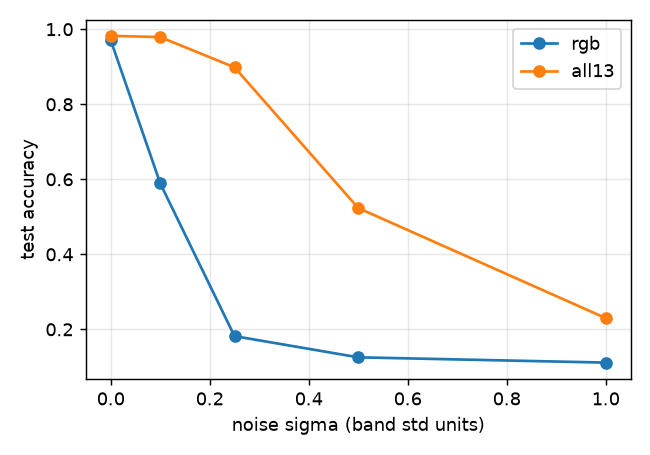

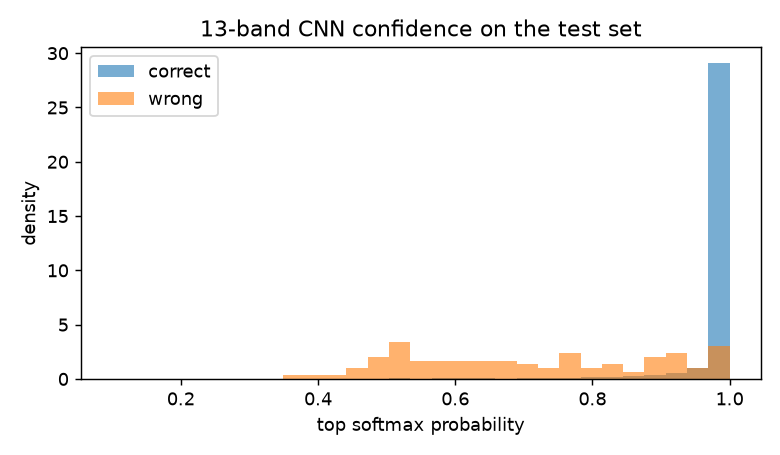

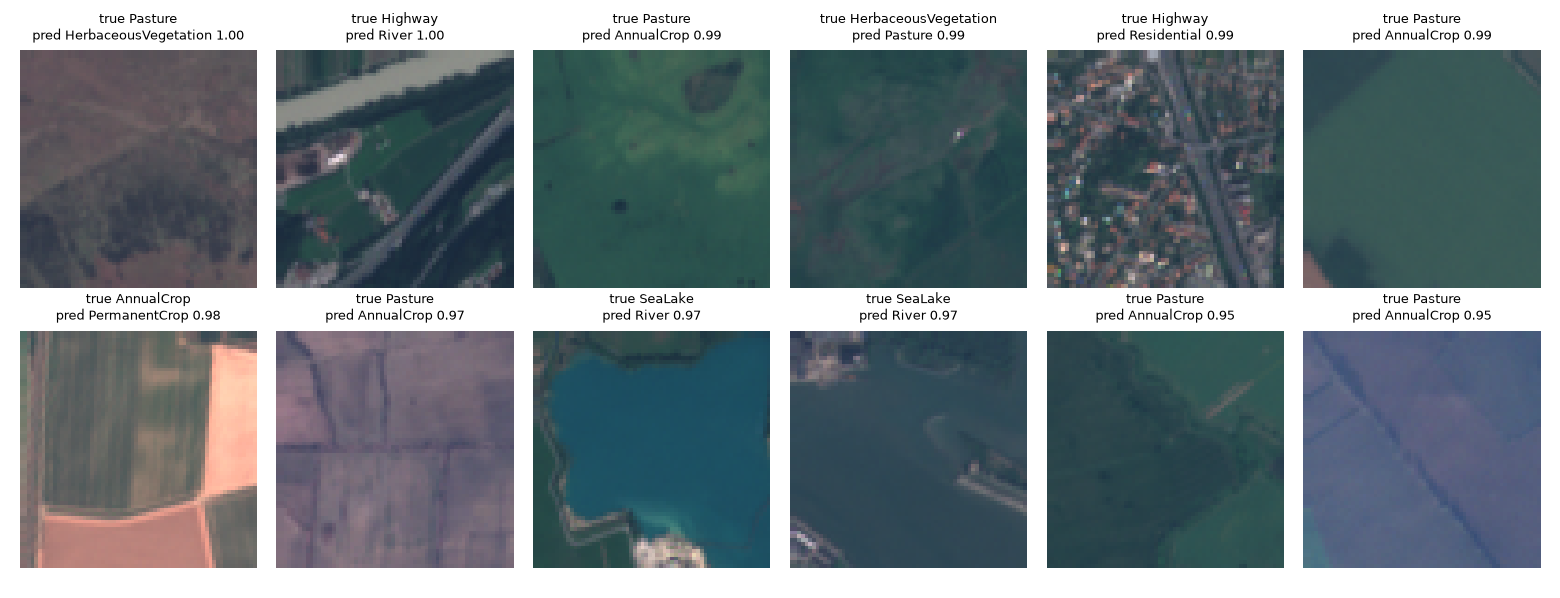

{
 "n_test": 5400,
 "n_wrong": 95,
 "median_conf_correct": 0.9990401864051819,
 "median_conf_wrong": 0.7038964629173279,
 "share_wrong_with_conf_over_0.9": 0.2,
 "top_confusions": [
  [
   "PermanentCrop",
   "AnnualCrop",
   9
  ],
  [
   "Highway",
   "River",
   7
  ],
  [
   "Pasture",
   "AnnualCrop",
   7
  ],
  [
   "PermanentCrop",
   "HerbaceousVegetation",
   7
  ],
  [
   "Highway",
   "Industrial",
   5
  ],
  [
   "Pasture",
   "HerbaceousVegetation",
   5
  ],
  [
   "AnnualCrop",
   "Pasture",
   4
  ],
  [
   "HerbaceousVegetation",
   "AnnualCrop",
   4
  ]
 ]
}


In [8]:
display(Image(RES + 'noise_curve.png'))
display(Image(RES + 'confidence_hist.png'))
display(Image(RES + 'confident_mistakes.png'))
print(json.dumps(json.load(open(RES + 'confidence.json')), indent=1))

## 5. Mine case study: Bingham Canyon, Utah
One Sentinel-2 L2A scene from Planetary Computer (6 Sep 2024). Labels are rectangles I drew by eye, with separate train and test boxes per class.

In [9]:
if RETRAIN:
    import get_scene, make_labels, mine
    get_scene.main(); make_labels.main(); mine.main()
print(json.dumps(json.load(open(RES + 'mine/mine_summary.json')), indent=1))
pd.read_csv(RES + 'mine/mine_report.csv', index_col=0)

{
 "heldout_acc": 0.7699,
 "pixels_train_test": {
  "pit": [
   4000,
   8000
  ],
  "waste_rock": [
   4000,
   12000
  ],
  "vegetation": [
   4000,
   16900
  ],
  "water": [
   360,
   154
  ],
  "built_up": [
   4000,
   12000
  ],
  "rangeland": [
   4000,
   22500
  ]
 },
 "map_share": {
  "pit": 0.0732,
  "waste_rock": 0.0805,
  "vegetation": 0.1995,
  "water": 0.0016,
  "built_up": 0.3702,
  "rangeland": 0.275
 },
 "feature_importance": {
  "B02": 0.102,
  "B03": 0.064,
  "B04": 0.057,
  "B05": 0.03,
  "B06": 0.046,
  "B07": 0.041,
  "B08": 0.061,
  "B8A": 0.051,
  "B11": 0.1,
  "B12": 0.076,
  "ndvi": 0.149,
  "ndwi": 0.166,
  "ndbi": 0.059
 }
}


,precision,recall,f1-score,support
pit,0.606,0.898,0.724,8000.00
waste_rock,0.927,0.638,0.756,12000.00
vegetation,0.684,0.956,0.797,16900.00
water,0.202,0.987,0.336,154.00
built_up,0.787,0.902,0.841,12000.00
rangeland,0.986,0.583,0.732,22500.00
accuracy,0.770,0.770,0.770,0.77
macro avg,0.699,0.827,0.698,71554.00
weighted avg,0.827,0.770,0.768,71554.00


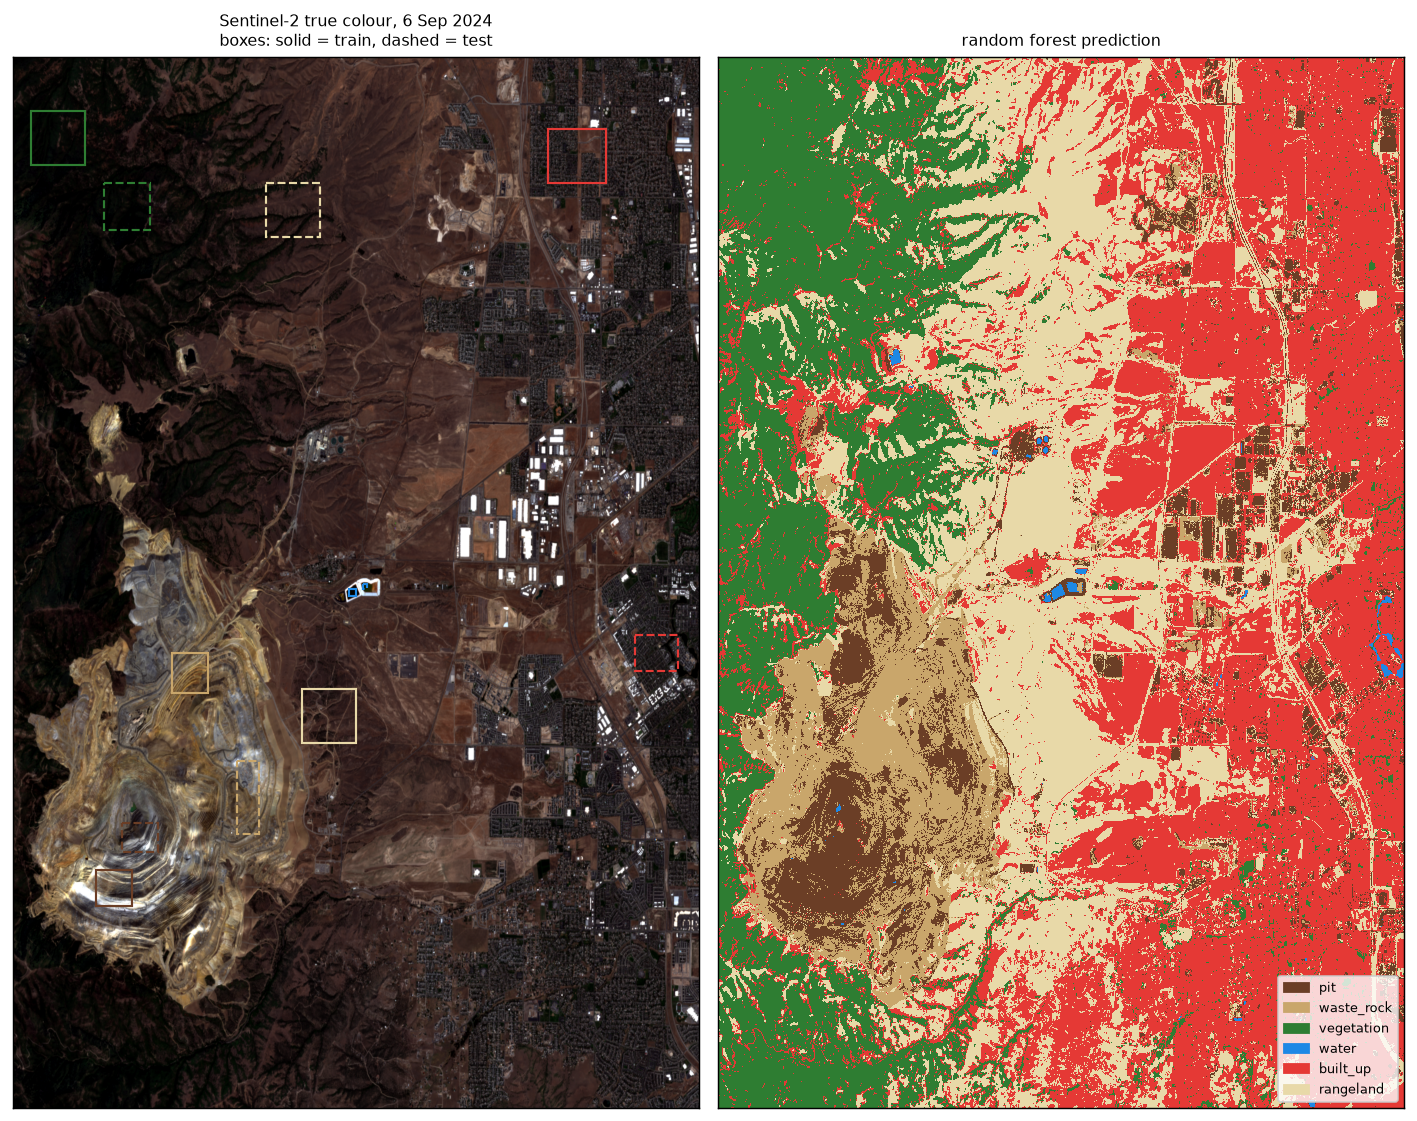

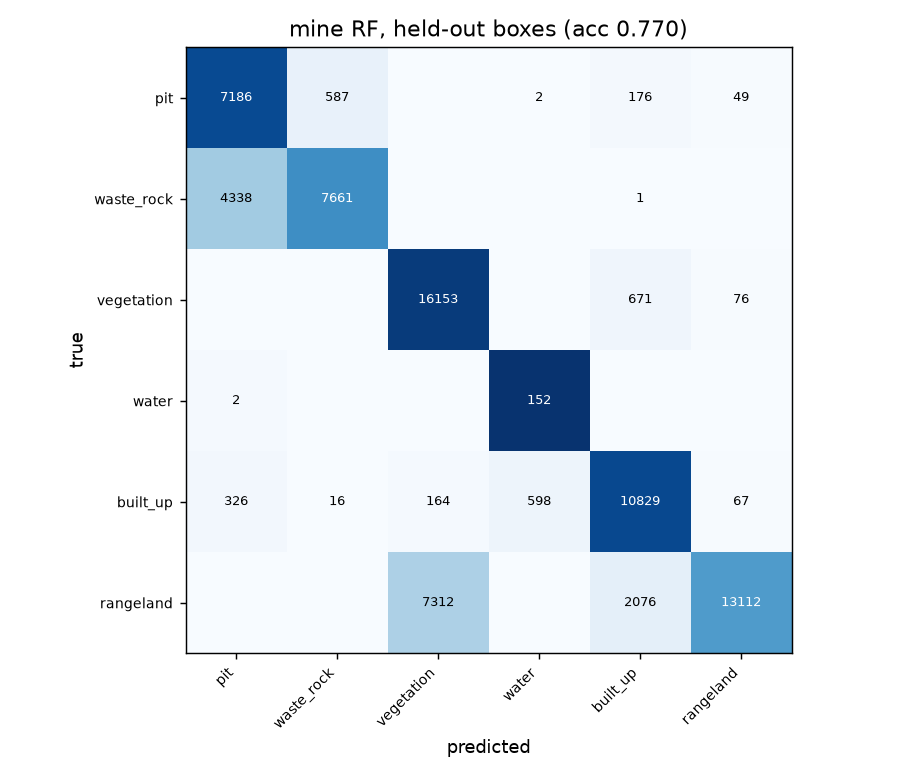

In [10]:
display(Image(RES + 'mine/mine_map.png'))
display(Image(RES + 'mine/cm_mine.png'))